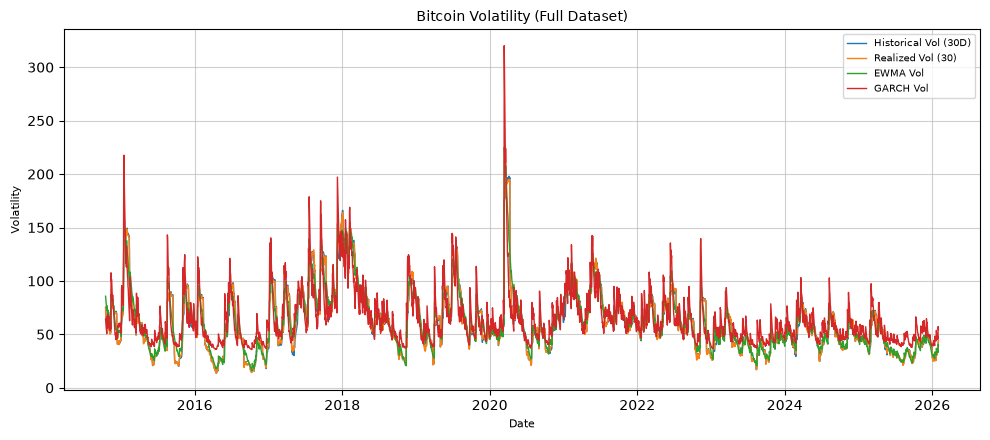

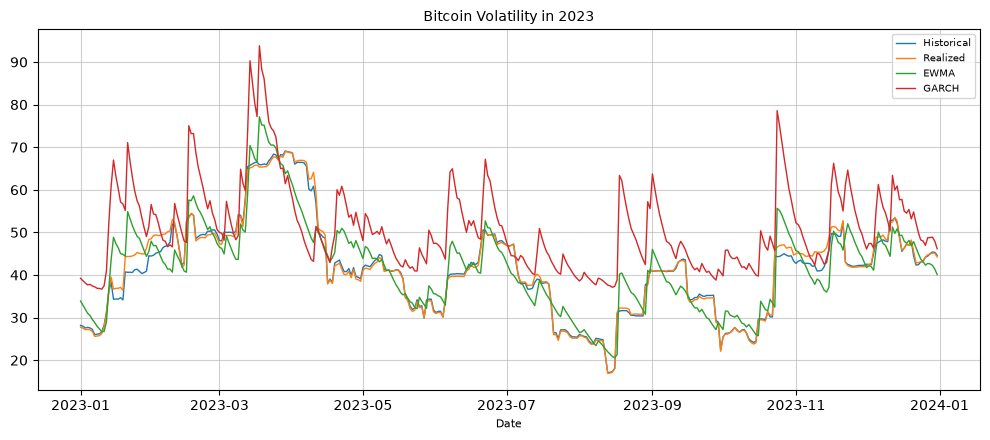

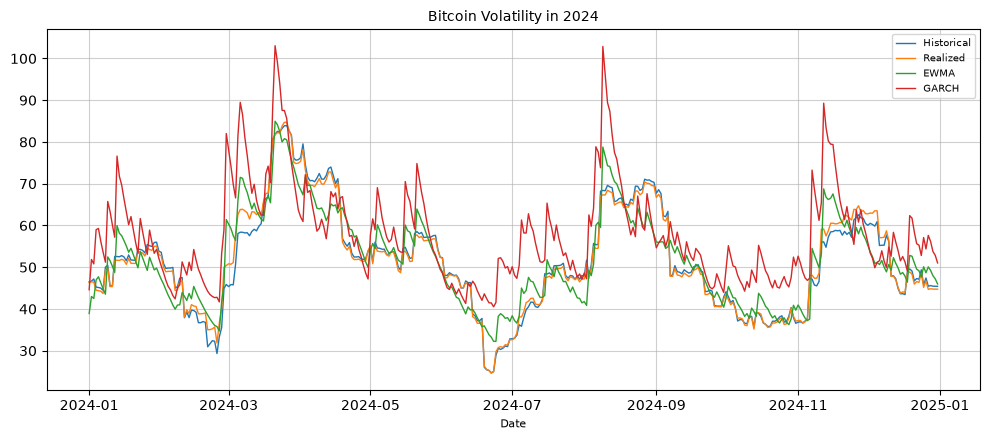

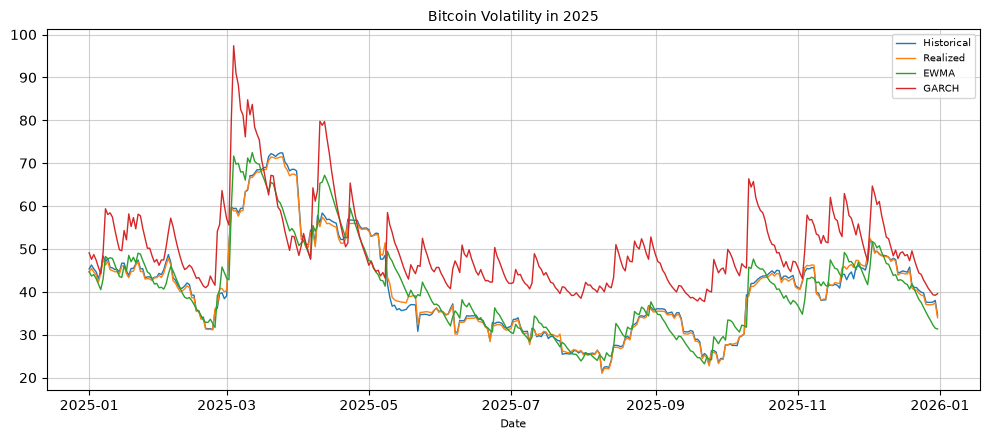

Volatility graphs completed.



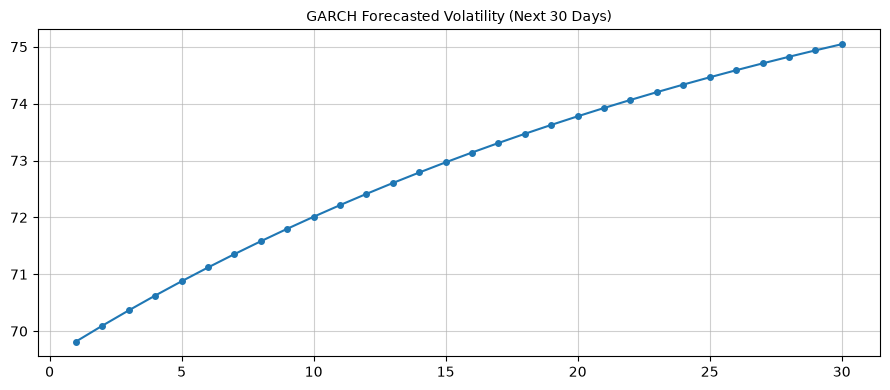

Training LSTM Model...

Epoch 1/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - loss: 0.0091
Epoch 2/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 0.0024
Epoch 3/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - loss: 0.0018
Epoch 4/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 0.0015
Epoch 5/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - loss: 0.0013
Epoch 6/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - loss: 0.0012
Epoch 7/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - loss: 0.0011
Epoch 8/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - loss: 9.5951e-04
Epoch 9/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 8.7560e-04
Epoch 10/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - loss: 8.0887e-04
Epoch 11/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - loss: 7.9399e-04
Epoch 12/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 6.6968e-04
Epoch 13/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 6.8949e-04
Epoch 14/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 6.

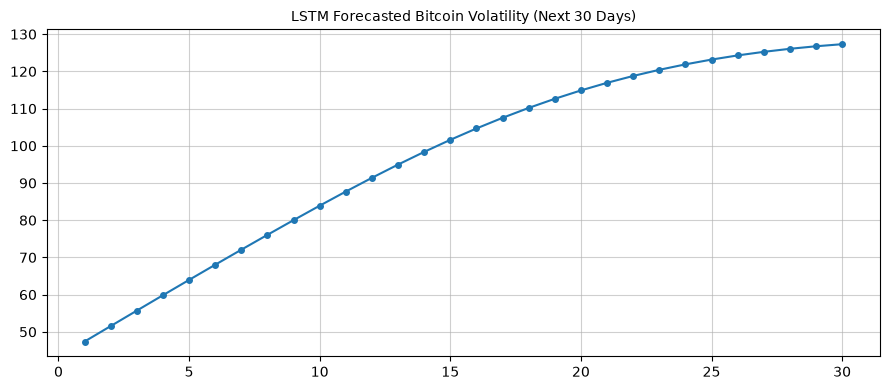


----- LSTM Forecast -----
1-Day  Vol: 47.3995
7-Day  Vol: 72.0764
30-Day Vol: 127.3115


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from arch import arch_model
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

print("Downloading Bitcoin historical data...")
btc = yf.download("BTC-USD", start="2014-09-17", end="2026-02-01", auto_adjust=False, progress=False)

if isinstance(btc.columns, pd.MultiIndex):
    btc.columns = btc.columns.get_level_values(0)
btc = btc.reset_index()

btc = btc[["Date", "Close"]].copy()
btc["Date"] = pd.to_datetime(btc["Date"], errors="coerce")
btc["Close"] = pd.to_numeric(btc["Close"], errors="coerce")
btc = btc.dropna(subset=["Date", "Close"]).sort_values("Date").reset_index(drop=True)

btc["Log_Return"] = np.log(btc["Close"] / btc["Close"].shift(1))
btc = btc.dropna(subset=["Log_Return"]).reset_index(drop=True)

window = 30
btc["Historical_Vol"] = btc["Log_Return"].rolling(window=window).std() * np.sqrt(365) * 100
btc["Realized_Vol"] = np.sqrt((btc["Log_Return"] ** 2).rolling(window=window).sum() * (365 / window)) * 100

lambda_val = 0.94
sq_ret = btc["Log_Return"] ** 2
ewma_var = np.zeros(len(btc))
ewma_var[0] = sq_ret.iloc[0]
for i in range(1, len(btc)):
    ewma_var[i] = lambda_val * ewma_var[i - 1] + (1 - lambda_val) * sq_ret.iloc[i - 1]

btc["EWMA_Vol"] = np.sqrt(ewma_var) * np.sqrt(365) * 100

scaled_returns = btc["Log_Return"] * 100
garch_model_fit = arch_model(scaled_returns, mean="Constant", vol="GARCH", p=1, q=1, dist="normal").fit(disp="off")
btc["GARCH_Vol"] = garch_model_fit.conditional_volatility * np.sqrt(365)

df_plot = btc.dropna().copy().reset_index(drop=True)

def plot_volatility_comparison(data, title, is_yearly=False):
    plt.figure(figsize=(10, 4.5))
    plt.plot(data["Date"], data["Historical_Vol"], label="Historical Vol (30D)" if not is_yearly else "Historical", linewidth=1)
    plt.plot(data["Date"], data["Realized_Vol"], label="Realized Vol (30)" if not is_yearly else "Realized", linewidth=1)
    plt.plot(data["Date"], data["EWMA_Vol"], label="EWMA Vol" if not is_yearly else "EWMA", linewidth=1)
    plt.plot(data["Date"], data["GARCH_Vol"], label="GARCH Vol" if not is_yearly else "GARCH", linewidth=1)
    plt.title(title, fontsize=10)
    plt.xlabel("Date", fontsize=8)
    plt.ylabel("Volatility" if not is_yearly else "", fontsize=8)
    plt.legend(loc="upper right", fontsize=7)
    plt.grid(True, linestyle="-", alpha=0.6)
    plt.tight_layout()
    plt.show()

plot_volatility_comparison(df_plot, "Bitcoin Volatility (Full Dataset)", is_yearly=False)

df_2023 = df_plot[(df_plot["Date"] >= "2023-01-01") & (df_plot["Date"] <= "2023-12-31")]
plot_volatility_comparison(df_2023, "Bitcoin Volatility in 2023", is_yearly=True)

df_2024 = df_plot[(df_plot["Date"] >= "2024-01-01") & (df_plot["Date"] <= "2024-12-31")]
plot_volatility_comparison(df_2024, "Bitcoin Volatility in 2024", is_yearly=True)

df_2025 = df_plot[(df_plot["Date"] >= "2025-01-01") & (df_plot["Date"] <= "2025-12-31")]
plot_volatility_comparison(df_2025, "Bitcoin Volatility in 2025", is_yearly=True)

print("Volatility graphs completed.\n")

garch_30_forecast = garch_model_fit.forecast(horizon=30, reindex=False)
garch_var_path = garch_30_forecast.variance.values[-1]
garch_30_days_vol = np.sqrt(garch_var_path) * np.sqrt(365)
days = np.arange(1, 31)

plt.figure(figsize=(9, 4))
plt.plot(days, garch_30_days_vol, marker="o", markersize=4, linestyle="-")
plt.title("GARCH Forecasted Volatility (Next 30 Days)", fontsize=10)
plt.xlabel("", fontsize=8)
plt.ylabel("", fontsize=8)
plt.grid(True, linestyle="-", alpha=0.6)
plt.tight_layout()
plt.show()

print("Training LSTM Model...\n")

vol_series = df_plot["Historical_Vol"].values.reshape(-1, 1)
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_vol = scaler.fit_transform(vol_series)

lookback = 30
X, y = [], []
for i in range(len(scaled_vol) - lookback):
    X.append(scaled_vol[i:i + lookback])
    y.append(scaled_vol[i + lookback])
X, y = np.array(X), np.array(y)

model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(lookback, 1)),
    LSTM(50),
    Dense(1)
])
model.compile(optimizer="adam", loss="mean_squared_error")

model.fit(X, y, epochs=20, batch_size=32, verbose=1)

last_seq = scaled_vol[-lookback:].copy().reshape(1, lookback, 1)
lstm_forecast_scaled = []
for _ in range(30):
    pred = model.predict(last_seq, verbose=0)[0, 0]
    lstm_forecast_scaled.append(pred)
    last_seq = np.append(last_seq[:, 1:, :], [[[pred]]], axis=1)

lstm_30_days_vol = scaler.inverse_transform(np.array(lstm_forecast_scaled).reshape(-1, 1)).flatten()

plt.figure(figsize=(9, 4))
plt.plot(days, lstm_30_days_vol, marker="o", markersize=4, linestyle="-")
plt.title("LSTM Forecasted Bitcoin Volatility (Next 30 Days)", fontsize=10)
plt.xlabel("", fontsize=8)
plt.ylabel("", fontsize=8)
plt.grid(True, linestyle="-", alpha=0.6)
plt.tight_layout()
plt.show()

print("\n----- LSTM Forecast -----")
print(f"1-Day  Vol: {lstm_30_days_vol[0]:.4f}")
print(f"7-Day  Vol: {lstm_30_days_vol[6]:.4f}")
print(f"30-Day Vol: {lstm_30_days_vol[29]:.4f}")
print("=" * 45)